In [43]:
from modules.data_loader import *
from rdkit import Chem
import numpy as np

## Data loading and cleaning from scratch for reproducibility

In [44]:
visco = pd.read_csv(DATA_DIR / 'Viscoelastic_WLM.csv')

In [45]:
d = {
    'Source': 'source',
    'ID_surfactant1' : 'id_surfactant1',
    'Type_surfactant1' : 'type_surfactant1',
    'SMILES_surfactant1' : 'smiles_surfactant1',
    'C_surfactant1 (mM)' : 'c_surfactant1',
    'ID_surfactant2' : 'id_surfactant2',
    'Type_surfactant2' : 'type_surfactant2',
    'SMILES_surfactant2' : 'smiles_surfactant2',
    'C_surfactant2 (mM)' : 'c_surfactant2',
    'ID_additive1' : 'id_additive1',
    'SMILES_additive1' : 'smiles_additive1',
    'C_additive1 (mM)' : 'c_additive1',
    'ID_additive2' : 'id_additive2',
    'SMILES_additive2' : 'smiles_additive2',
    'C_additive2 (mM)' : 'c_additive2',
    'T [°C]' : 'temperature',
    'Viscoelasticity' : 'viscoelasticity',
    'G₀  [Pa]' : 'g_0',
    'G"min [Pa]' : 'g_min',
    'ω* cr [rad/s]' : 'omega_cr',
    'ͳR [s]' : 'tau_r',
    'η₀[Pa∙s]' : 'eta_0'
}

visco = visco.rename(columns = d)

In [46]:
visco = visco.dropna(subset=['viscoelasticity'])

In [47]:
visco[['c_surfactant1', 'c_surfactant2', 'c_additive1', 'c_additive2']] = visco[['c_surfactant1', 'c_surfactant2', 'c_additive1', 'c_additive2']].fillna(0)

In [48]:
visco = visco.query("source != 'A81'")
visco = visco.query("source != 'A118'")
visco = visco.query("source != 'A85'")

In [49]:
def validate_smiles(smiles):
    if pd.isna(smiles):
        return True
    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        return False
    return True

def correct_smiles(smiles):
    if smiles == 'CCCCCCCCCCCCCCCCOCC(O)CN+(C)C.[Br-]':
        return 'CCCCCCCCCCCCCCCCOCC(O)C[N+](C)C.[Br-]'
    elif smiles == 'CCCCCCCCCCCCCCCCN+(C)C.[Cl-]':
        return 'CCCCCCCCCCCCCCCC[N+](C)C.[Cl-]'
    elif smiles == 'CCCCCCCCCCCCCCCCN+(C)C.[Br-]':
        return 'CCCCCCCCCCCCCCCC[N+](C)C.[Br-]'
    elif smiles == 'CCCCCCCCCCCC(=O)NCCCN+(C)C([O-])=O':
        return 'CCCCCCCCCCCC(=O)NCCC[N+](C)C([O-])=O'
    elif smiles == 'CCCCCCCCCCCC(=O)NCCCN+(C)(C)CC([O-])=O':
        return 'CCCCCCCCCCCC(=O)NCCC[N+](C)(C)CC([O-])=O'
    elif smiles == '[Al+3].[O-]N+[O-].[O-]N+[O-].[O-]N+[O-]':
        return '[Al+3].[O-][N+][O-].[O-][N+][O-].[O-][N+][O-]'
    elif smiles == '[Na+].[O-]N+[O-]':
        return '[Na+].[O-][N+][O-]'
    elif smiles == 'CCCCCC1C(CCCCCC(=O)NCCCN(C)(C)CC(=O)[O-])C(C=CC1CCCCCC)CCCCCC(=O)NCCCN(C)(C)CC(=O)[O-]':
        return 'CCCCCCCCCCCC[N+](C)(C)CC(=O)[O-]'
    return smiles

In [50]:
visco['smiles_surfactant1'] = visco['smiles_surfactant1'].apply(correct_smiles)
visco['smiles_surfactant2'] = visco['smiles_surfactant2'].apply(correct_smiles)
visco['smiles_additive1'] = visco['smiles_additive1'].apply(correct_smiles)
visco['smiles_additive2'] = visco['smiles_additive2'].apply(correct_smiles)

In [51]:
smiles = list(visco['smiles_surfactant1'].unique())
smiles.extend(visco['smiles_surfactant2'].unique())
smiles.extend(visco['smiles_additive1'].unique())
smiles.extend(visco['smiles_additive2'].unique())
len(smiles)
for smile in smiles:
    if not validate_smiles(smile):
        print(smile)

In [52]:
def smiles_to_canonical(smiles):
    if pd.isna(smiles):
        return smiles
    return Chem.MolToSmiles(Chem.MolFromSmiles(smiles))

In [53]:
columns = ['smiles_surfactant1', 'smiles_surfactant2','smiles_additive1', 'smiles_additive2']
visco[columns] = visco[columns].apply(lambda col: col.map(smiles_to_canonical))

In [54]:
visco = visco.drop_duplicates(subset=visco.columns.difference(['source']))

## Maxwell equation checking

In [55]:
viscoelastic = visco.loc[(visco['viscoelasticity'] == 1.0) & (visco['tau_r'] != 0)].copy()

In [56]:
viscoelastic["calc_eta"] = viscoelastic["g_0"] * viscoelastic["tau_r"]

In [57]:
viscoelastic["pct_error"] = abs(viscoelastic["eta_0"] - viscoelastic["calc_eta"]) / viscoelastic["eta_0"]*100
viscoelastic["abs_diff"] = abs(viscoelastic["eta_0"] - viscoelastic["calc_eta"])


threshold_pct = viscoelastic["pct_error"].quantile(0.97)
threshold_abs = viscoelastic["abs_diff"].quantile(0.97)

<Axes: title={'center': 'Distribution of Calculation Errors'}, ylabel='Frequency'>

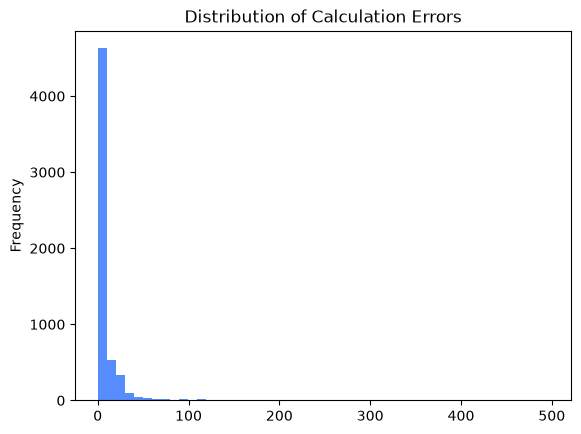

In [58]:
viscoelastic["pct_error"].plot.hist(bins=50, title="Distribution of Calculation Errors")

<Axes: title={'center': 'Distribution of Calculation Errors'}, ylabel='Frequency'>

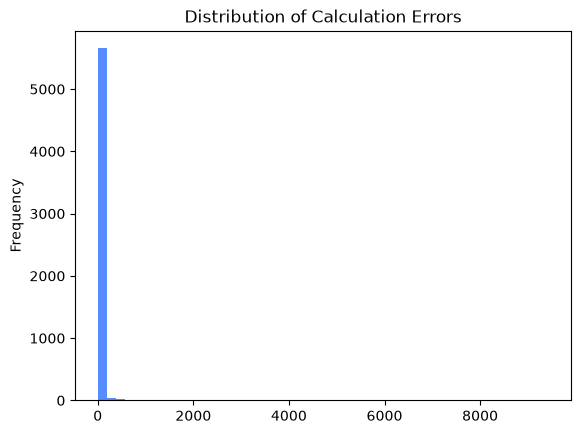

In [59]:
viscoelastic["abs_diff"].plot.hist(bins=50, title="Distribution of Calculation Errors")

In [60]:
viscoelastic.sort_values(by="pct_error", ascending=False)

,source,id_surfactant1,type_surfactant1,smiles_surfactant1,c_surfactant1,id_surfactant2,type_surfactant2,smiles_surfactant2,c_surfactant2,id_additive1,...,temperature,viscoelasticity,g_0,g_min,omega_cr,tau_r,eta_0,calc_eta,pct_error,abs_diff
952,A22,DAB,zwitterionic,CCCCCCCCCCCC[N+](C)(C)CC(=O)[O-],50.00,NaN,NaN,NaN,0.0,NaCl,...,20,1.0,34.000,1.9720,0.0030,333.33,1900.0000,11333.2200,496.485263,9433.22
951,A22,DAB,zwitterionic,CCCCCCCCCCCC[N+](C)(C)CC(=O)[O-],50.00,NaN,NaN,NaN,0.0,NaCl,...,20,1.0,28.000,1.7080,0.0050,200.00,1320.0000,5600.0000,324.242424,4280.00
3629,A76,SLSar,anionic,CCCCCCCCCCCC(=O)N(C)CC(=O)[O-].[Na+],204.51,CAHS_C12_proxy,zwitterionic,CCCCCCCCCCCC(=O)NCCC[N+](C)(C)CC(O)CS(=O)(=O)[O-],212.9,Citric_acid,...,25,1.0,401.000,85.0000,65.0000,0.02,2.0000,8.0200,301.000000,6.02
2633,A43,CPyCl,cationic,CCCCCCCCCCCCCCCC[n+]1ccccc1.[Cl-],5.00,NaN,NaN,NaN,0.0,NaDi,...,25,1.0,0.100,0.0260,0.0400,25.00,0.6500,2.5000,284.615385,1.85
947,A22,DAB,zwitterionic,CCCCCCCCCCCC[N+](C)(C)CC(=O)[O-],50.00,NaN,NaN,NaN,0.0,NaCl,...,20,1.0,29.000,2.3200,0.0110,90.91,920.0000,2636.3900,186.564130,1716.39
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2375,A40,CTAT,cationic,CCCCCCCCCCCCCCCC[N+](C)(C)C.Cc1ccc(S(=O)(=O)[O...,548.55,NaN,NaN,NaN,0.0,NaN,...,35,1.0,1000.000,228.3500,14.2850,0.07,70.0000,70.0000,0.000000,0.00
2371,A40,CTAT,cationic,CCCCCCCCCCCCCCCC[N+](C)(C)C.Cc1ccc(S(=O)(=O)[O...,109.71,NaN,NaN,NaN,0.0,NaN,...,35,1.0,70.000,5.5994,1.3157,0.76,53.2000,53.2000,0.000000,0.00
5306,A91,CTAB,cationic,CCCCCCCCCCCCCCCC[N+](C)(C)C.[Br-],100.00,NaN,NaN,NaN,0.0,NaSal,...,40,1.0,30.743,5.1219,10.0000,0.10,3.0743,3.0743,0.000000,0.00
1797,A32,SLES,anionic,CCCCCCCCCCCCOCCOS(=O)(=O)[O-].[Na+],395.00,CAPB,zwitterionic,CCCCCCCCCCCC(=O)NCCC[N+](C)C(=O)[O-],55.0,NaCl,...,25,1.0,4.500,1.5000,100.0000,0.01,0.0450,0.0450,0.000000,0.00


In [61]:
viscoelastic[viscoelastic["source"]=="A88"]

,source,id_surfactant1,type_surfactant1,smiles_surfactant1,c_surfactant1,id_surfactant2,type_surfactant2,smiles_surfactant2,c_surfactant2,id_additive1,...,temperature,viscoelasticity,g_0,g_min,omega_cr,tau_r,eta_0,calc_eta,pct_error,abs_diff
4769,A88,CTASal,cationic,CCCCCCCCCCCCCCCC[N+](C)(C)C.O=C([O-])c1ccccc1O,4.7431,NaN,NaN,NaN,0.0,NaSal,...,44,1.0,0.0483,0.0048,3.3543,0.30,0.0086,0.014490,68.488372,0.005890
4770,A88,CTASal,cationic,CCCCCCCCCCCCCCCC[N+](C)(C)C.O=C([O-])c1ccccc1O,4.7431,NaN,NaN,NaN,0.0,NaSal,...,45,1.0,0.0479,0.0047,3.3941,0.29,0.0081,0.013891,71.493827,0.005791
4771,A88,CTASal,cationic,CCCCCCCCCCCCCCCC[N+](C)(C)C.O=C([O-])c1ccccc1O,4.7431,NaN,NaN,NaN,0.0,NaSal,...,46,1.0,0.0475,0.0047,3.4343,0.29,0.0076,0.013775,81.250000,0.006175
4772,A88,CTASal,cationic,CCCCCCCCCCCCCCCC[N+](C)(C)C.O=C([O-])c1ccccc1O,4.7431,NaN,NaN,NaN,0.0,NaSal,...,47,1.0,0.0471,0.0047,3.4750,0.29,0.0071,0.013659,92.380282,0.006559
4773,A88,CTASal,cationic,CCCCCCCCCCCCCCCC[N+](C)(C)C.O=C([O-])c1ccccc1O,4.7431,NaN,NaN,NaN,0.0,NaSal,...,48,1.0,0.0467,0.0046,3.5161,0.28,0.0067,0.013076,95.164179,0.006376
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5020,A88,CTASal,cationic,CCCCCCCCCCCCCCCC[N+](C)(C)C.O=C([O-])c1ccccc1O,4.7431,NaN,NaN,NaN,0.0,NaSal,...,60,1.0,0.0297,0.0029,3.6986,0.27,0.0054,0.008019,48.500000,0.002619
5021,A88,CTASal,cationic,CCCCCCCCCCCCCCCC[N+](C)(C)C.O=C([O-])c1ccccc1O,4.7431,NaN,NaN,NaN,0.0,NaSal,...,60,1.0,0.0289,0.0028,3.7187,0.27,0.0049,0.007803,59.244898,0.002903
5022,A88,CTASal,cationic,CCCCCCCCCCCCCCCC[N+](C)(C)C.O=C([O-])c1ccccc1O,4.7431,NaN,NaN,NaN,0.0,NaSal,...,60,1.0,0.0281,0.0028,3.7388,0.27,0.0044,0.007587,72.431818,0.003187
5023,A88,CTASal,cationic,CCCCCCCCCCCCCCCC[N+](C)(C)C.O=C([O-])c1ccccc1O,4.7431,NaN,NaN,NaN,0.0,NaSal,...,60,1.0,0.0274,0.0027,3.7591,0.27,0.0039,0.007398,89.692308,0.003498


In [62]:
outliers = viscoelastic[
    (viscoelastic["pct_error"] > threshold_pct)
    & (viscoelastic["abs_diff"] > 2.0)
].sort_values(by="pct_error", ascending=False)

outliers

,source,id_surfactant1,type_surfactant1,smiles_surfactant1,c_surfactant1,id_surfactant2,type_surfactant2,smiles_surfactant2,c_surfactant2,id_additive1,...,temperature,viscoelasticity,g_0,g_min,omega_cr,tau_r,eta_0,calc_eta,pct_error,abs_diff
952,A22,DAB,zwitterionic,CCCCCCCCCCCC[N+](C)(C)CC(=O)[O-],50.000,NaN,NaN,NaN,0.000,NaCl,...,20,1.0,34.000,1.9720,0.0030,333.33,1900.000,11333.22000,496.485263,9433.22000
951,A22,DAB,zwitterionic,CCCCCCCCCCCC[N+](C)(C)CC(=O)[O-],50.000,NaN,NaN,NaN,0.000,NaCl,...,20,1.0,28.000,1.7080,0.0050,200.00,1320.000,5600.00000,324.242424,4280.00000
3629,A76,SLSar,anionic,CCCCCCCCCCCC(=O)N(C)CC(=O)[O-].[Na+],204.510,CAHS_C12_proxy,zwitterionic,CCCCCCCCCCCC(=O)NCCC[N+](C)(C)CC(O)CS(=O)(=O)[O-],212.900,Citric_acid,...,25,1.0,401.000,85.0000,65.0000,0.02,2.000,8.02000,301.000000,6.02000
947,A22,DAB,zwitterionic,CCCCCCCCCCCC[N+](C)(C)CC(=O)[O-],50.000,NaN,NaN,NaN,0.000,NaCl,...,20,1.0,29.000,2.3200,0.0110,90.91,920.000,2636.39000,186.564130,1716.39000
950,A22,DAB,zwitterionic,CCCCCCCCCCCC[N+](C)(C)CC(=O)[O-],50.000,NaN,NaN,NaN,0.000,NaCl,...,20,1.0,27.000,1.7280,0.0070,142.86,1350.000,3857.22000,185.720000,2507.22000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6197,A103,SDSS,anionic,CCCCCCCCCCCCOC1COC2C(OS(=O)(=O)[O-])COC12.[Na+],96.756,5-DS,nonionic,CCCCCCCCCCCCOC1COC2C(O)COC12,30.840,NaCl,...,25,1.0,35.309,6.3557,1.6123,0.62,15.573,21.89158,40.573942,6.31858
6684,A111,CTAT,cationic,CCCCCCCCCCCCCCCC[N+](C)(C)C.Cc1ccc(S(=O)(=O)[O...,31.267,SDBS,anionic,CCCCCCCCCCCCc1ccc(S(=O)(=O)[O-])cc1.[Na+],59.467,NaN,...,25,1.0,5.200,0.2860,0.0200,50.00,185.000,260.00000,40.540541,75.00000
1105,A27,EHAC,cationic,CCCCCCCC/C=C\CCCCCCCCCCCC[N+](C)(CCO)CCO.[Cl-],60.000,NaN,NaN,NaN,0.000,NaSal,...,36,1.0,10.283,0.8710,0.0010,1000.00,17195.000,10283.00000,40.197732,6912.00000
571,A13,CTAB,cationic,CCCCCCCCCCCCCCCC[N+](C)C.[Br-],350.000,NaN,NaN,NaN,0.000,KBr,...,35,1.0,149.900,55.4000,50.0000,0.02,5.000,2.99800,40.040000,2.00200


In [63]:
save_features(outliers.drop(columns=["pct_error", "abs_diff", "calc_eta"]), 'outliers')